In [1]:
# !pip show torch
!pip install pandas==2.2.3 transformers==5.16.1 arabert==1.0.1 torch==2.11.0+cpu

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.0/185.0 kB 8.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 96.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 179.3/179.3 kB 15.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.4/126.4 kB 10.6 MB/s eta 0:00:00
  Created wheel for emoji: filename=emoji-1.4.2-py3-none-any.whl size=186540 sha256=bcbcf499f0552d1ee8055f956aa215a62b6cbd1036d4bb530473f31b76d40416
  Stored in directory: /root/.cache/pip/wheels/e1/79/2a/9864bac03173079abcc089d3eb3ec87456ac09c381b801f1a3
Successfully built emoji
  Attempting uninstall: transformers
    Found existing installation: transformers 5.18.0
    Uninstalling transformers-5.18.0:
      Successfully uninstalled transformers-5.18.0


In [ ]:
import pandas as pd
from transformers import AutoTokenizer
from arabert.preprocess import ArabertPreprocessor
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, random_split
import torch.nn.functional as F
import matplotlib.pylab as plt

In [ ]:
%%time
%pip install pandas numpy==1.26.4 seaborn==0.9.0 matplotlib scikit-learn pmdarima portalocker>=2.0.0 plotly dash
%pip install torch==2.3.0+cpu torchdata==0.9.0+cpu torchtext==0.18.0+cpu \
    --index-url https://download.pytorch.org/whl/cpu

In [ ]:
from tqdm import tqdm
import numpy as np
import pandas as pd
from itertools import accumulate
import matplotlib.pyplot as plt
from torchtext.data.utils import get_tokenizer

import torch
from torch import nn

from torch.utils.data import DataLoader
import numpy as np
from torchtext.datasets import AG_NEWS
from IPython.display import Markdown as md
from tqdm import tqdm

from torchtext.vocab import build_vocab_from_iterator
from torchtext.datasets import AG_NEWS
from torch.utils.data.dataset import random_split
from torchtext.data.functional import to_map_style_dataset
from sklearn.manifold import TSNE
import plotly.graph_objs as go
from sklearn.model_selection import train_test_split

from torchtext.data.utils import get_tokenizer


# You can also use this section to suppress warnings generated by your code:
def warn(*args, **kwargs):
    pass


import warnings

warnings.warn = warn
warnings.filterwarnings("ignore")

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [97]:
torch.manual_seed(42)

In [ ]:
df = pd.read_csv(
    "./drive/MyDrive/Tech/dvc/mlops_course/files/md5/76/c7390ffb33bc987c4bec67889971ef.tmp",
    encoding="cp1256",
)

In [26]:
df.head()

,Polarity,Review Text
0,0,ينتن!: شهور من التهوية لا يمكن أن تسلب الرائحة...
1,0,مخيبة للآمال: كانت هذه روايتي الأولى لدانييل س...
2,0,اشتريت هذا الخلاط. بعد بضعة أشهر من الاستخدام ...
3,0,ليست خلاطا للفواكه المجمدة: اشتريت هذا الخلاط ...
4,0,مخيب جدا للآمال! يؤلم أذنيك. وصلني كهدية عيد ا...


In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Polarity     5000 non-null   int64 
 1   Review Text  5000 non-null   object
dtypes: int64(1), object(1)
memory usage: 78.3+ KB


In [28]:
model_name = "aubmindlab/bert-base-arabertv02"

In [20]:
arabert_prep = ArabertPreprocessor(model_name=model_name)
tokenizer = AutoTokenizer.from_pretrained(model_name)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/384 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/381 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/825k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.64M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [200]:
input_dim = 128
hidden_dim = 10
output_dim = 2

In [201]:
df_tokenized = df.copy()

In [202]:
def tokenize_text(data):
    return tokenizer(
        arabert_prep.preprocess(data),
        max_length=input_dim,
        padding="max_length",
        truncation=True,
    )

In [ ]:
df_tokenized["Review"] = df_tokenized["Review Text"].apply(lambda x: tokenize_text(x))

In [204]:
df_tokenized.head()

,Polarity,Review Text,Review
0,0,ينتن!: شهور من التهوية لا يمكن أن تسلب الرائحة...,"[input_ids, token_type_ids, attention_mask]"
1,0,مخيبة للآمال: كانت هذه روايتي الأولى لدانييل س...,"[input_ids, token_type_ids, attention_mask]"
2,0,اشتريت هذا الخلاط. بعد بضعة أشهر من الاستخدام ...,"[input_ids, token_type_ids, attention_mask]"
3,0,ليست خلاطا للفواكه المجمدة: اشتريت هذا الخلاط ...,"[input_ids, token_type_ids, attention_mask]"
4,0,مخيب جدا للآمال! يؤلم أذنيك. وصلني كهدية عيد ا...,"[input_ids, token_type_ids, attention_mask]"


In [ ]:
class Data(Dataset):
    def __init__(self, df):
        self.x = df["Review"][:10]
        self.y = df["Polarity"][:10]

    def __getitem__(self, index):
        return self.x[index], self.y[index]

    def __len__(self):
        return len(self.x)

In [206]:
dataset = Data(df_tokenized)

In [ ]:
x, y = dataset[1]
print(x["input_ids"])
print(x["token_type_ids"])
print(x["attention_mask"])

[2, 45602, 35894, 31, 678, 450, 7215, 9662, 1163, 1240, 431, 349, 47684, 103, 4275, 42035, 37577, 13582, 15082, 35865, 4243, 8930, 310, 20, 678, 3766, 672, 13418, 24434, 9383, 6933, 15679, 228, 816, 655, 4609, 103, 732, 2886, 418, 305, 921, 5046, 360, 33006, 4848, 20, 28083, 6375, 1447, 12514, 32515, 20, 15082, 547, 1422, 2776, 30030, 31759, 1163, 3360, 306, 8222, 3292, 20, 1217, 2776, 1090, 12236, 47064, 306, 1325, 5074, 3351, 15556, 3472, 7085, 40467, 197, 6357, 103, 391, 50266, 193, 2397, 2886, 20, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 

In [208]:
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

In [209]:
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

In [ ]:
class MyModel(nn.Module):
    def __init__(self, in_size, n_hidden, out_size, p=0):
        super().__init__()
        # self.drop = nn.Dropout(p=p)
        # self.linear1 = nn.Linear(in_size, n_hidden)
        # self.linear2 = nn.Linear(n_hidden, n_hidden)
        # self.linear3 = nn.Linear(n_hidden, out_size)
        self.linear3 = nn.Linear(in_size, out_size)

    def forward(self, x):
        # x = F.relu(self.drop(self.linear1(x)))
        # x = F.relu(self.drop(self.linear2(x)))
        # x = self.linear3(x)
        x = self.linear3(x)
        return x

In [211]:
model = MyModel(input_dim, hidden_dim, output_dim, 0.1)

In [212]:
learning_rate = 0.1
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
criterion = nn.CrossEntropyLoss()
train_loader = torch.utils.data.DataLoader(dataset=train_dataset, batch_size=1)
val_loader = torch.utils.data.DataLoader(dataset=val_dataset, batch_size=5000)

In [ ]:
n_epochs = 10
loss_list = []
accuracy_list = []
N_test = len(val_dataset)


def train_model(n_epochs):
    for epoch in range(n_epochs):
        for x, y in train_loader:
            optimizer.zero_grad()
            z = model(torch.Tensor(x["input_ids"]))
            print(z, y)
            loss = criterion(z, torch.tensor(y).squeeze())
            loss.backward()
            optimizer.step()

        correct = 0
        for x_test, y_test in val_loader:
            z = model(torch.Tensor(x["input_ids"]))
            yhat = torch.max(z.data)
            correct += (yhat == torch.tensor(y_test).squeeze()).sum().item()
        print(loss.data)
        accuracy = correct / N_test
        print(accuracy)
        loss_list.append(loss.data)
        accuracy_list.append(accuracy)


train_model(n_epochs)

tensor([2718.5708,  516.5031], grad_fn=<ViewBackward0>) tensor([0])
tensor([-261.4096, 2250.1868], grad_fn=<ViewBackward0>) tensor([0])
tensor([ 1.8447e+08, -1.8447e+08], grad_fn=<ViewBackward0>) tensor([0])
tensor([ 1.9433e+08, -1.9433e+08], grad_fn=<ViewBackward0>) tensor([0])
tensor([ 2.8398e+08, -2.8398e+08], grad_fn=<ViewBackward0>) tensor([0])
tensor([ 64647768., -64665020.], grad_fn=<ViewBackward0>) tensor([0])
tensor([ 46617200., -46620488.], grad_fn=<ViewBackward0>) tensor([0])
tensor([ 64647768., -64665020.], grad_fn=<ViewBackward0>) tensor([0])
tensor(0.)
0.0
tensor([ 1.5007e+08, -1.5007e+08], grad_fn=<ViewBackward0>) tensor([0])
tensor([ 8.8603e+08, -8.8603e+08], grad_fn=<ViewBackward0>) tensor([0])
tensor([ 1.8447e+08, -1.8447e+08], grad_fn=<ViewBackward0>) tensor([0])
tensor([ 1.9433e+08, -1.9433e+08], grad_fn=<ViewBackward0>) tensor([0])
tensor([ 2.8398e+08, -2.8398e+08], grad_fn=<ViewBackward0>) tensor([0])
tensor([ 64647768., -64665020.], grad_fn=<ViewBackward0>) tenso

/tmp/ipykernel_1016/2543761347.py:12: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  loss = criterion(z, torch.tensor(y).squeeze())
/tmp/ipykernel_1016/2543761347.py:20: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  correct += (yhat == torch.tensor(y_test).squeeze()).sum().item()


tensor([ 8.8603e+08, -8.8603e+08], grad_fn=<ViewBackward0>) tensor([0])
tensor([ 1.8447e+08, -1.8447e+08], grad_fn=<ViewBackward0>) tensor([0])
tensor([ 1.9433e+08, -1.9433e+08], grad_fn=<ViewBackward0>) tensor([0])
tensor([ 2.8398e+08, -2.8398e+08], grad_fn=<ViewBackward0>) tensor([0])
tensor([ 64647768., -64665020.], grad_fn=<ViewBackward0>) tensor([0])
tensor([ 46617200., -46620488.], grad_fn=<ViewBackward0>) tensor([0])
tensor([ 64647768., -64665020.], grad_fn=<ViewBackward0>) tensor([0])
tensor(0.)
0.0
tensor([ 1.5007e+08, -1.5007e+08], grad_fn=<ViewBackward0>) tensor([0])
tensor([ 8.8603e+08, -8.8603e+08], grad_fn=<ViewBackward0>) tensor([0])
tensor([ 1.8447e+08, -1.8447e+08], grad_fn=<ViewBackward0>) tensor([0])
tensor([ 1.9433e+08, -1.9433e+08], grad_fn=<ViewBackward0>) tensor([0])
tensor([ 2.8398e+08, -2.8398e+08], grad_fn=<ViewBackward0>) tensor([0])
tensor([ 64647768., -64665020.], grad_fn=<ViewBackward0>) tensor([0])
tensor([ 46617200., -46620488.], grad_fn=<ViewBackward0>)

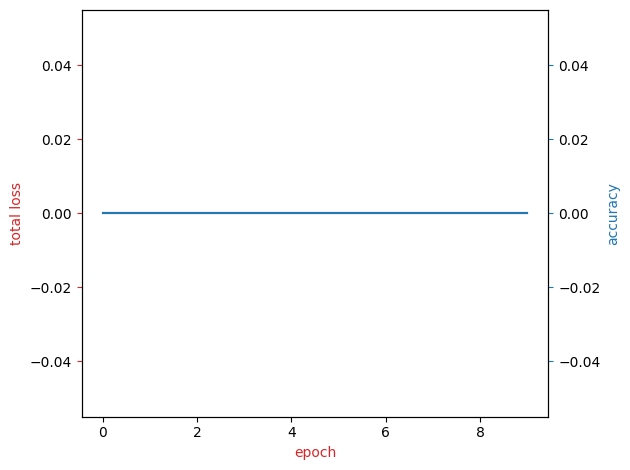

In [ ]:
fig, ax1 = plt.subplots()
color = "tab:red"
ax1.plot(loss_list, color=color)
ax1.set_xlabel("epoch", color=color)
ax1.set_ylabel("total loss", color=color)
ax1.tick_params(axis="y", color=color)

ax2 = ax1.twinx()
color = "tab:blue"
ax2.set_ylabel("accuracy", color=color)
ax2.plot(accuracy_list, color=color)
ax2.tick_params(axis="y", color=color)
fig.tight_layout()